In [1]:
!pip install mysql-connector-python

In [2]:
import mysql.connector
import pandas as pd
import matplotlib.pyplot as plt

# Connect to VivPay database
conn = mysql.connector.connect(
    host="localhost",
    user="root",
    password="betroot",
    database="financial_operations"
)

print("Connected to VivPay database successfully!")

Connected to VivPay database successfully!


In [3]:
import mysql.connector
import pandas as pd

# Function to load a MySQL table into a DataFrame
def load_table(table_name):
    cursor = conn.cursor()
    cursor.execute(f"SELECT * FROM `{table_name}`")

    columns = [column[0] for column in cursor.description]
    rows = cursor.fetchall()

    cursor.close()

    return pd.DataFrame(rows, columns=columns)

# Load all four tables
customers = load_table("customers")
transactions = load_table("transactions")
fraud_alerts = load_table("fraud_alerts")
service_cases = load_table("service_cases")

print("Customers:", customers.shape)
print("Transactions:", transactions.shape)
print("Fraud Alerts:", fraud_alerts.shape)
print("Service Cases:", service_cases.shape)

print("All tables loaded successfully!")

Customers: (1186, 9)
Transactions: (6822, 10)
Fraud Alerts: (1084, 8)
Service Cases: (2356, 11)
All tables loaded successfully!


In [4]:
import os

os.makedirs("visualizations", exist_ok=True)

print("Visualizations folder created successfully!")
print("Folder location:", os.path.abspath("visualizations"))

Visualizations folder created successfully!
Folder location: C:\Users\sadan\Python - batch 267\VivPay project\visualizations


In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# Professional financial dashboard palette
COLORS = {
    "blue": "#2563EB",
    "teal": "#0F766E",
    "green": "#16A34A",
    "orange": "#EA580C",
    "red": "#DC2626",
    "purple": "#7C3AED",
    "pink": "#DB2777",
    "cyan": "#0891B2",
    "gold": "#CA8A04",
    "slate": "#64748B"
}

# Consistent chart styling
sns.set_theme(style="whitegrid", context="notebook")

plt.rcParams.update({
    "figure.figsize": (9, 5),
    "figure.dpi": 110,
    "savefig.dpi": 300,
    "axes.titlesize": 15,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "grid.alpha": 0.25
})

print("Professional visualization style applied!")

Professional visualization style applied!


In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

# Professional chart style without gridlines
sns.set_style("white")

plt.rcParams.update({
    "axes.grid": False,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white"
})

## Customer analytics
### Chart 1: Customers by segment

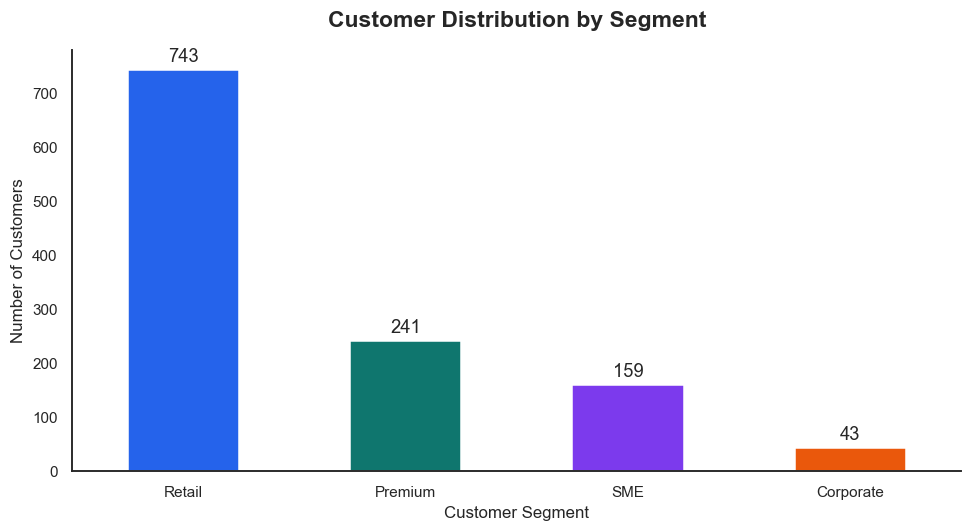

In [7]:
ax = customers["customer_segment"].value_counts().plot(
    kind="bar",
    color=["#2563EB", "#0F766E", "#7C3AED", "#EA580C"],
    edgecolor="white",
    figsize=(9, 5)
)

ax.set_title("Customer Distribution by Segment", pad=15)
ax.set_xlabel("Customer Segment")
ax.set_ylabel("Number of Customers")
ax.bar_label(ax.containers[0], padding=3, fmt="%d")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("visualizations/01_customers_by_segment.png", bbox_inches="tight")
plt.show()

## Chart 2 — KYC status

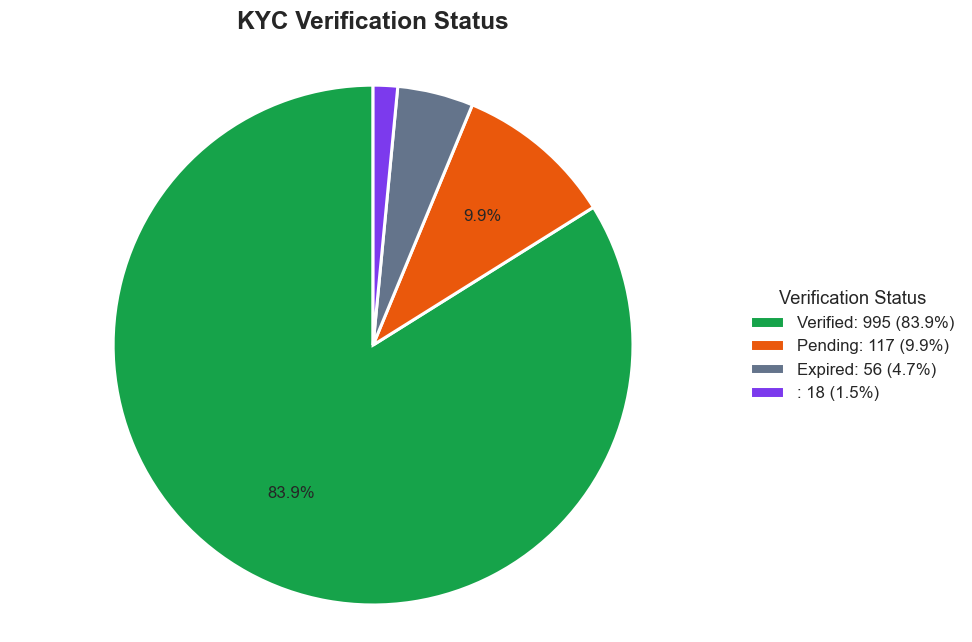

In [8]:
kyc_counts = customers["kyc_status"].fillna("Unknown").value_counts()

fig, ax = plt.subplots(figsize=(9, 6))

colors = ["#16A34A", "#EA580C", "#64748B", "#7C3AED", "#0891B2"]

wedges, texts, autotexts = ax.pie(
    kyc_counts,
    labels=None,
    autopct=lambda pct: f"{pct:.1f}%" if pct >= 5 else "",
    startangle=90,
    colors=colors[:len(kyc_counts)],
    pctdistance=0.65,
    wedgeprops={"edgecolor": "white", "linewidth": 2},
    textprops={"fontsize": 11}
)

ax.set_title("KYC Verification Status", fontsize=16, fontweight="bold", pad=20)

# Put status names and counts in a legend
legend_labels = [
    f"{status}: {count:,} ({count / kyc_counts.sum() * 100:.1f}%)"
    for status, count in kyc_counts.items()
]

ax.legend(
    wedges,
    legend_labels,
    title="Verification Status",
    loc="center left",
    bbox_to_anchor=(1, 0.5),
    frameon=False
)

ax.axis("equal")
plt.tight_layout()
plt.savefig(
    "visualizations/02_kyc_status.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)
plt.show()

## Chart 3 — Customer age distribution 

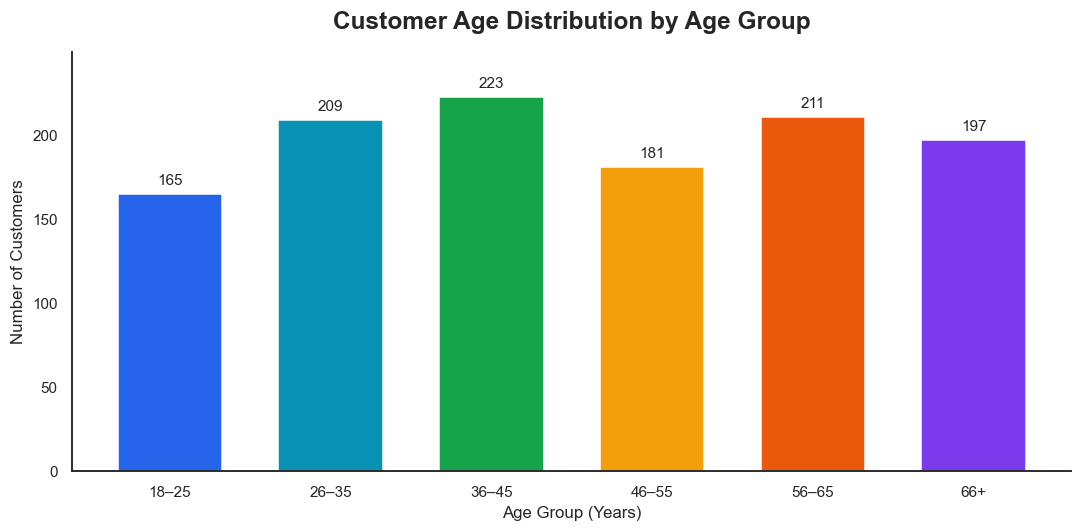

In [9]:

import pandas as pd
import matplotlib.pyplot as plt

# Convert age to numeric
customers["age"] = pd.to_numeric(customers["age"], errors="coerce")

# Remove missing ages
age_data = customers["age"].dropna()

# Group ages into ranges
bins = [0, 25, 35, 45, 55, 65, 100]
labels = [
    "18–25",
    "26–35",
    "36–45",
    "46–55",
    "56–65",
    "66+"
]

age_groups = pd.cut(
    age_data,
    bins=bins,
    labels=labels,
    include_lowest=True
)

age_counts = age_groups.value_counts().reindex(labels, fill_value=0)

# Colors: distinct and easy to understand
colors = [
    "#2563EB",
    "#0891B2",
    "#16A34A",
    "#F59E0B",
    "#EA580C",
    "#7C3AED"
]

fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.bar(
    age_counts.index.astype(str),
    age_counts.values,
    color=colors,
    width=0.65
)

ax.set_title(
    "Customer Age Distribution by Age Group",
    fontsize=16,
    fontweight="bold",
    pad=15
)
ax.set_xlabel("Age Group (Years)")
ax.set_ylabel("Number of Customers")

# Display customer counts above each bar
ax.bar_label(bars, padding=4, fontsize=10)

# Clean chart
ax.grid(False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.margins(y=0.12)

plt.tight_layout()

plt.savefig(
    "visualizations/03_customer_age.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

# Transaction analytics
## Chart 4 — Transaction status


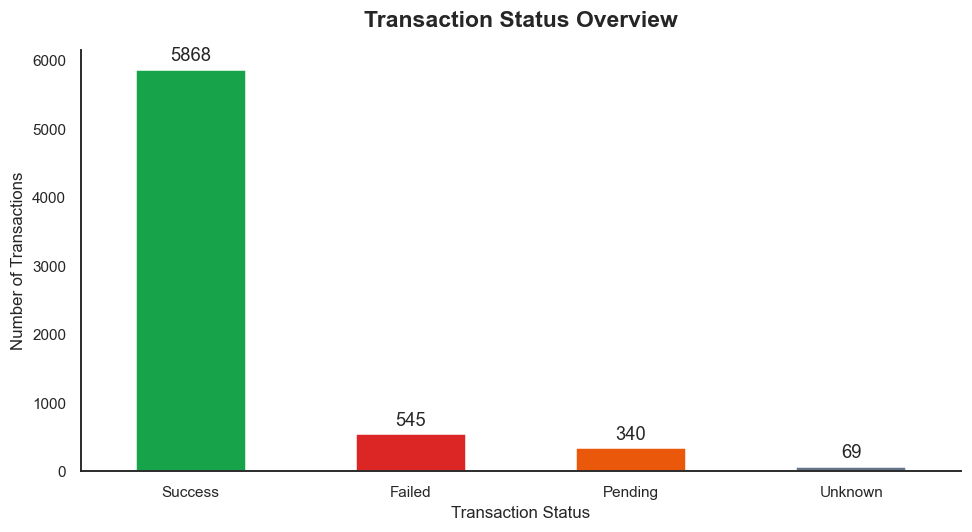

In [10]:
counts = transactions["transaction_status"].fillna("Unknown").value_counts()

ax = counts.plot(
    kind="bar",
    color=["#16A34A", "#DC2626", "#EA580C", "#64748B"][:len(counts)],
    edgecolor="white",
    figsize=(9, 5)
)
ax.set_title("Transaction Status Overview", pad=15, fontweight="bold")
ax.set_xlabel("Transaction Status")
ax.set_ylabel("Number of Transactions")
ax.bar_label(ax.containers[0], padding=3, fmt="%d")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("visualizations/04_transaction_status.png", bbox_inches="tight")
plt.show()

## Chart 5 — Transaction amount by payment channel

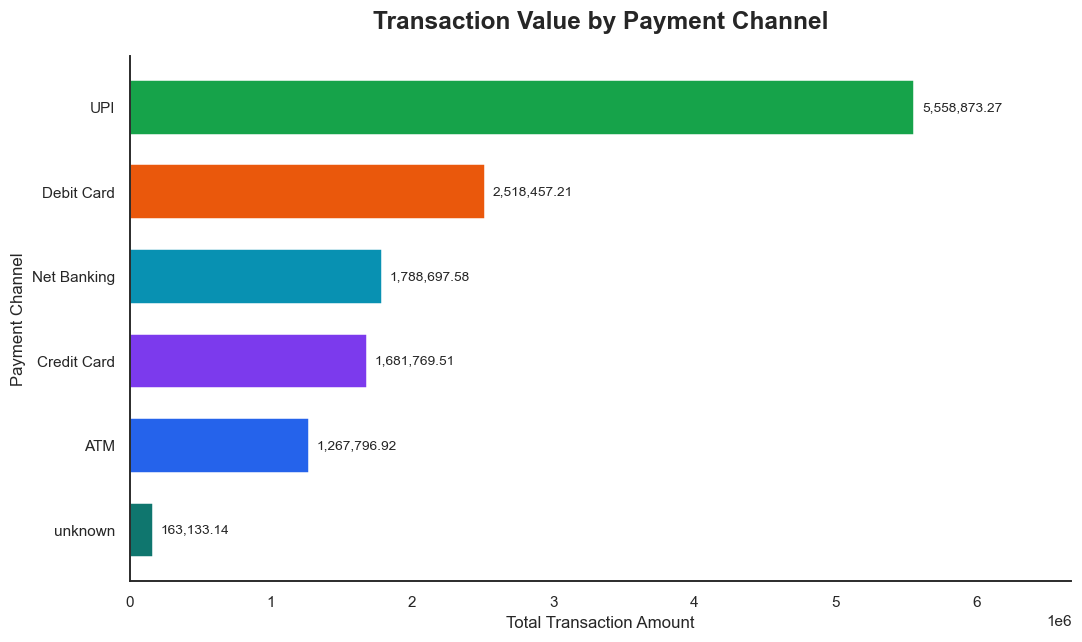

In [11]:
import pandas as pd
import matplotlib.pyplot as plt

# Standardize payment channel names
transactions["payment_channel"] = (
    transactions["payment_channel"]
    .astype("string")
    .str.strip()
    .str.lower()
    .replace({
        "credit_card": "Credit Card",
        "credit card": "Credit Card",
        "debit_card": "Debit Card",
        "debit card": "Debit Card",
        "upi": "UPI",
        "net banking": "Net Banking",
        "net_banking": "Net Banking",
        "atm": "ATM",
        "": pd.NA
    })
)

# Convert amount to numeric
transactions["amount"] = pd.to_numeric(
    transactions["amount"].astype(str).str.replace(",", "", regex=False),
    errors="coerce"
)

# Group after standardizing names
channel_amount = (
    transactions.dropna(subset=["payment_channel", "amount"])
    .groupby("payment_channel")["amount"]
    .sum()
    .sort_values()
)

# Different professional colors
colors = [
    "#0F766E", "#2563EB", "#7C3AED",
    "#0891B2", "#EA580C", "#16A34A"
]

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.barh(
    channel_amount.index,
    channel_amount.values,
    color=colors[:len(channel_amount)],
    edgecolor="white",
    height=0.65
)

ax.set_title(
    "Transaction Value by Payment Channel",
    fontsize=16,
    fontweight="bold",
    pad=18
)
ax.set_xlabel("Total Transaction Amount")
ax.set_ylabel("Payment Channel")

ax.bar_label(
    bars,
    labels=[f"{v:,.2f}" for v in channel_amount.values],
    padding=5,
    fontsize=9
)

ax.grid(False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.margins(x=0.2)

plt.tight_layout()
plt.savefig(
    "visualizations/05_payment_channel_amount.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)
plt.show()

## Chart 6: Daily transaction amount

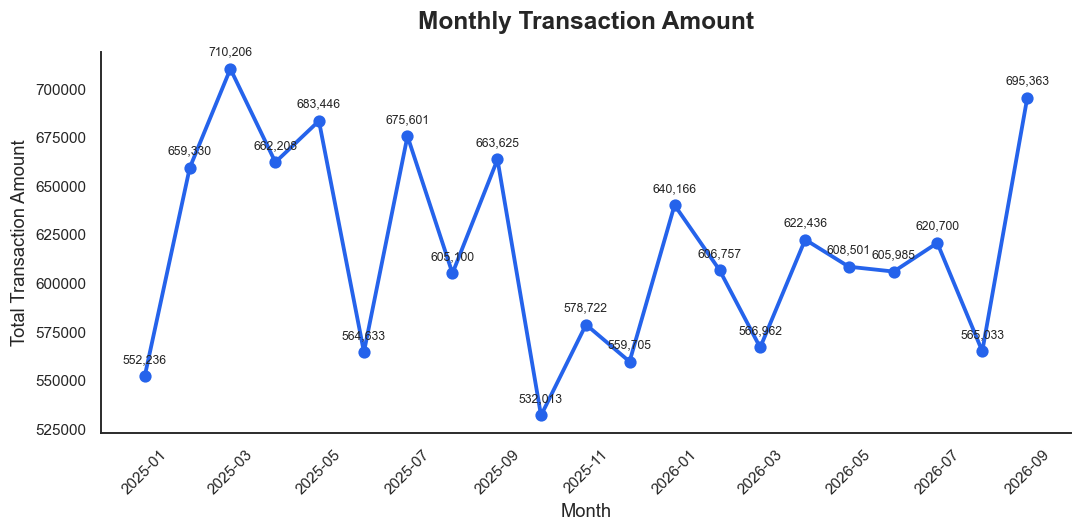

In [12]:
import pandas as pd
import matplotlib.pyplot as plt

# Convert columns to correct data types
transactions["transaction_timestamp"] = pd.to_datetime(
    transactions["transaction_timestamp"], errors="coerce"
)

transactions["amount"] = pd.to_numeric(
    transactions["amount"], errors="coerce"
)

# Calculate monthly transaction amount
monthly_amount = (
    transactions.dropna(subset=["transaction_timestamp", "amount"])
    .set_index("transaction_timestamp")["amount"]
    .resample("MS")
    .sum()
)

# Create an easy-to-understand chart
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    monthly_amount.index,
    monthly_amount.values,
    color="#2563EB",
    marker="o",
    linewidth=2.5,
    markersize=7
)

ax.set_title(
    "Monthly Transaction Amount",
    fontsize=16,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Month", fontsize=12)
ax.set_ylabel("Total Transaction Amount", fontsize=12)

# Display values above each point
for date, amount in monthly_amount.items():
    ax.annotate(
        f"{amount:,.0f}",
        (date, amount),
        xytext=(0, 9),
        textcoords="offset points",
        ha="center",
        fontsize=8
    )

# Remove gridlines
ax.grid(False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    "visualizations/06_monthly_transaction_amount.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

## Chart 7 — Transaction status by payment channel

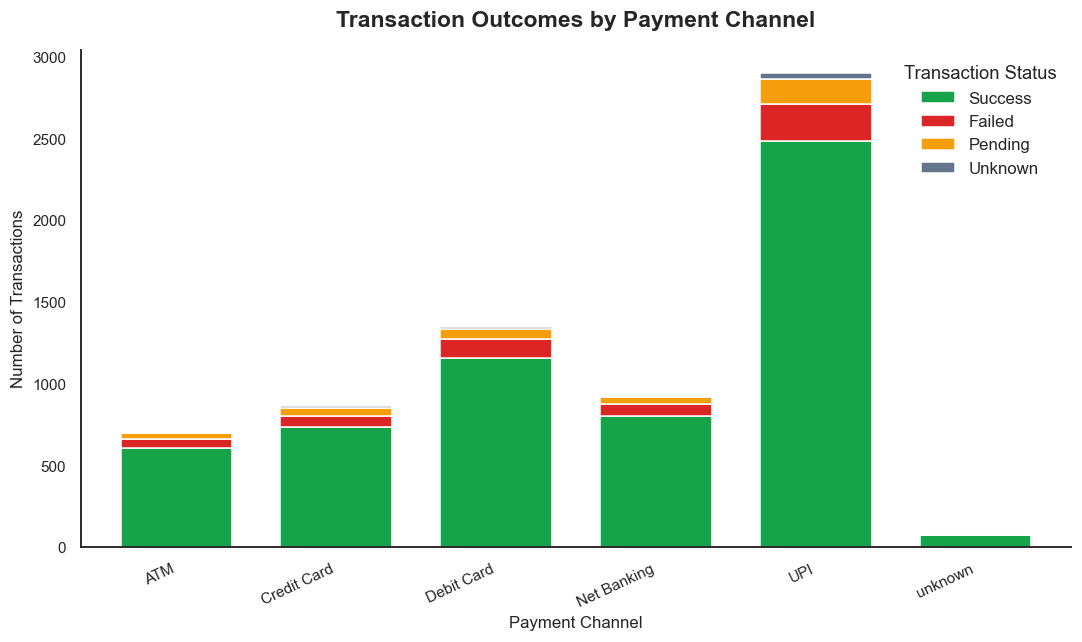

In [13]:

import matplotlib.pyplot as plt
import pandas as pd

# Standardize labels
transactions["transaction_status"] = (
    transactions["transaction_status"]
    .astype("string")
    .str.strip()
    .str.title()
)

transactions["payment_channel"] = (
    transactions["payment_channel"]
    .astype("string")
    .str.strip()
    .str.lower()
    .replace({
        "credit_card": "Credit Card",
        "credit card": "Credit Card",
        "debit_card": "Debit Card",
        "debit card": "Debit Card",
        "net_banking": "Net Banking",
        "net banking": "Net Banking",
        "upi": "UPI",
        "atm": "ATM",
        "": "Unknown"
    })
)

# Fixed status colors
status_colors = {
    "Success": "#16A34A",  # Green
    "Failed": "#DC2626",   # Red
    "Pending": "#F59E0B",  # Orange
    "Unknown": "#64748B"   # Grey
}

# Count transactions by channel and status
outcomes = pd.crosstab(
    transactions["payment_channel"],
    transactions["transaction_status"]
)

# Apply the fixed colors in the correct order
status_order = ["Success", "Failed", "Pending", "Unknown"]
outcomes = outcomes.reindex(columns=status_order, fill_value=0)

fig, ax = plt.subplots(figsize=(10, 6))

outcomes.plot(
    kind="bar",
    stacked=True,
    ax=ax,
    color=[status_colors[s] for s in status_order],
    edgecolor="white",
    width=0.7
)

ax.set_title(
    "Transaction Outcomes by Payment Channel",
    fontsize=15,
    fontweight="bold",
    pad=15
)
ax.set_xlabel("Payment Channel")
ax.set_ylabel("Number of Transactions")
ax.legend(title="Transaction Status", frameon=False)

# Clean appearance
ax.grid(False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.xticks(rotation=25, ha="right")
plt.tight_layout()

plt.savefig(
    "visualizations/07_transaction_outcomes.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)
plt.show()

## Chart 8 — Fraud alerts by risk level

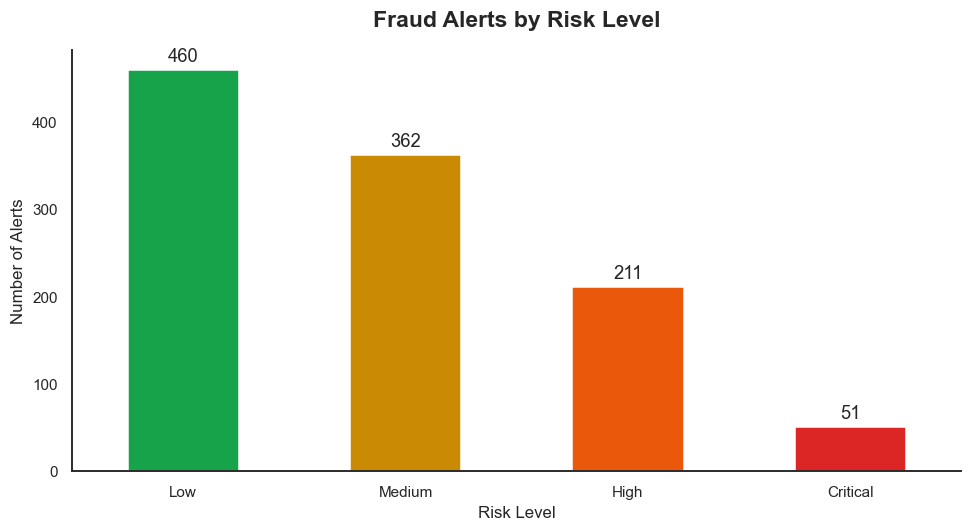

In [14]:
risk_counts = fraud_alerts["risk_level"].fillna("Unknown").value_counts()

risk_colors = {
    "Low": "#16A34A",
    "Medium": "#CA8A04",
    "High": "#EA580C",
    "Critical": "#DC2626",
    "Unknown": "#64748B"
}

ax = risk_counts.plot(
    kind="bar",
    color=[risk_colors.get(str(x).title(), "#64748B") for x in risk_counts.index],
    figsize=(9, 5),
    edgecolor="white"
)
ax.set_title("Fraud Alerts by Risk Level", pad=15, fontweight="bold")
ax.set_xlabel("Risk Level")
ax.set_ylabel("Number of Alerts")
ax.bar_label(ax.containers[0], padding=3, fmt="%d")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("visualizations/08_fraud_risk_levels.png", bbox_inches="tight")
plt.show()

## Chart 9 — Fraud anomaly scores

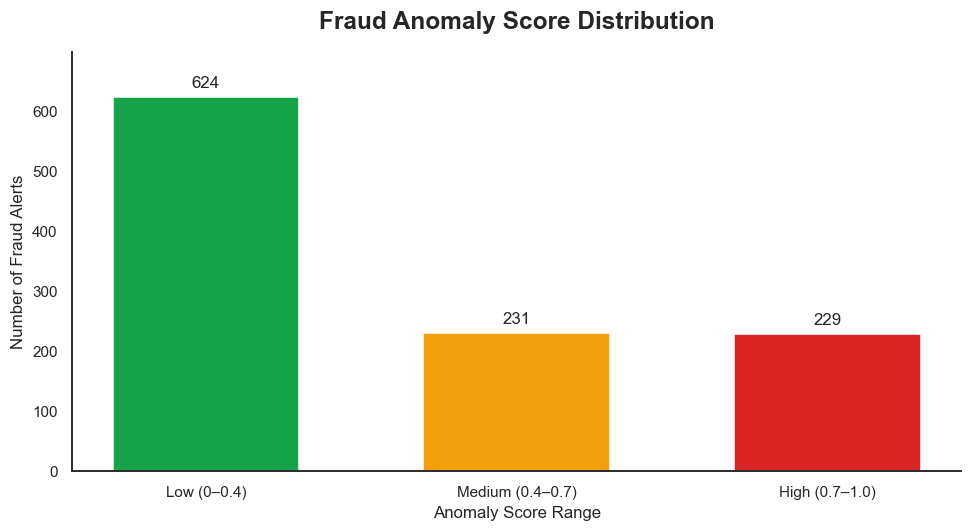

In [15]:

import pandas as pd
import matplotlib.pyplot as plt

# Convert anomaly scores to numeric
fraud_alerts["anomaly_score"] = pd.to_numeric(
    fraud_alerts["anomaly_score"],
    errors="coerce"
)

scores = fraud_alerts["anomaly_score"].dropna()

# Group scores into understandable ranges
bins = [0, 0.4, 0.7, 1.0]
labels = ["Low (0–0.4)", "Medium (0.4–0.7)", "High (0.7–1.0)"]

score_groups = pd.cut(
    scores,
    bins=bins,
    labels=labels,
    include_lowest=True,
    right=True
)

score_counts = score_groups.value_counts().reindex(labels, fill_value=0)

# Clear colors: green, orange, red
colors = ["#16A34A", "#F59E0B", "#DC2626"]

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    score_counts.index.astype(str),
    score_counts.values,
    color=colors,
    width=0.6
)

ax.set_title(
    "Fraud Anomaly Score Distribution",
    fontsize=16,
    fontweight="bold",
    pad=15
)
ax.set_xlabel("Anomaly Score Range")
ax.set_ylabel("Number of Fraud Alerts")

# Show counts above bars
ax.bar_label(bars, padding=4, fontsize=11)

# Remove gridlines and top/right borders
ax.grid(False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.margins(y=0.12)

plt.tight_layout()
plt.savefig(
    "visualizations/09_anomaly_score_distribution.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)
plt.show()

## Chart 10 — Fraud investigation status

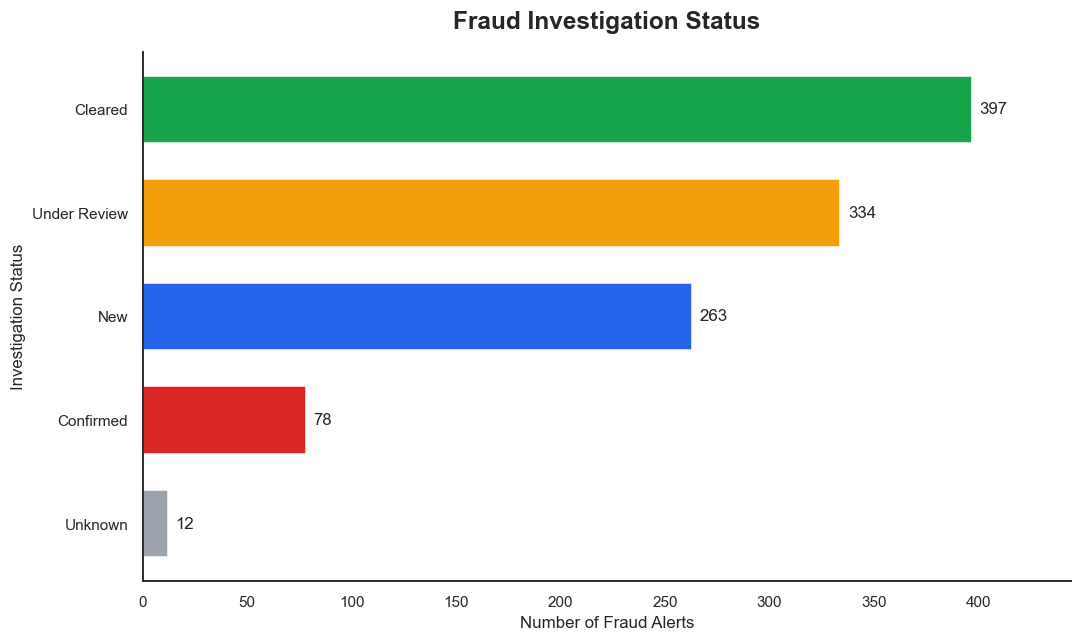

In [16]:

import pandas as pd
import matplotlib.pyplot as plt

# Clean investigation status
fraud_alerts["investigation_status"] = (
    fraud_alerts["investigation_status"]
    .astype("string")
    .str.strip()
    .str.title()
    .replace("", pd.NA)
    .fillna("Unknown")
)

# Count alerts by investigation status
status_counts = fraud_alerts["investigation_status"].value_counts()

# Easy-to-understand colors
status_colors = {
    "Cleared": "#16A34A",       # Green
    "Confirmed": "#DC2626",     # Red
    "Under Review": "#F59E0B",  # Orange
    "New": "#2563EB",           # Blue
    "Unknown": "#9CA3AF"        # Grey
}

# Sort from most alerts to fewest
status_counts = status_counts.sort_values(ascending=True)

colors = [
    status_colors.get(status, "#64748B")
    for status in status_counts.index
]

# Create horizontal bar chart
fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.barh(
    status_counts.index,
    status_counts.values,
    color=colors,
    height=0.65
)

ax.set_title(
    "Fraud Investigation Status",
    fontsize=16,
    fontweight="bold",
    pad=15
)
ax.set_xlabel("Number of Fraud Alerts")
ax.set_ylabel("Investigation Status")

# Display counts beside each bar
ax.bar_label(bars, padding=5, fontsize=11)

# Clean presentation
ax.grid(False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.margins(x=0.12)

plt.tight_layout()

plt.savefig(
    "visualizations/10_fraud_investigation_status.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

## Chart 11 — Service cases by type

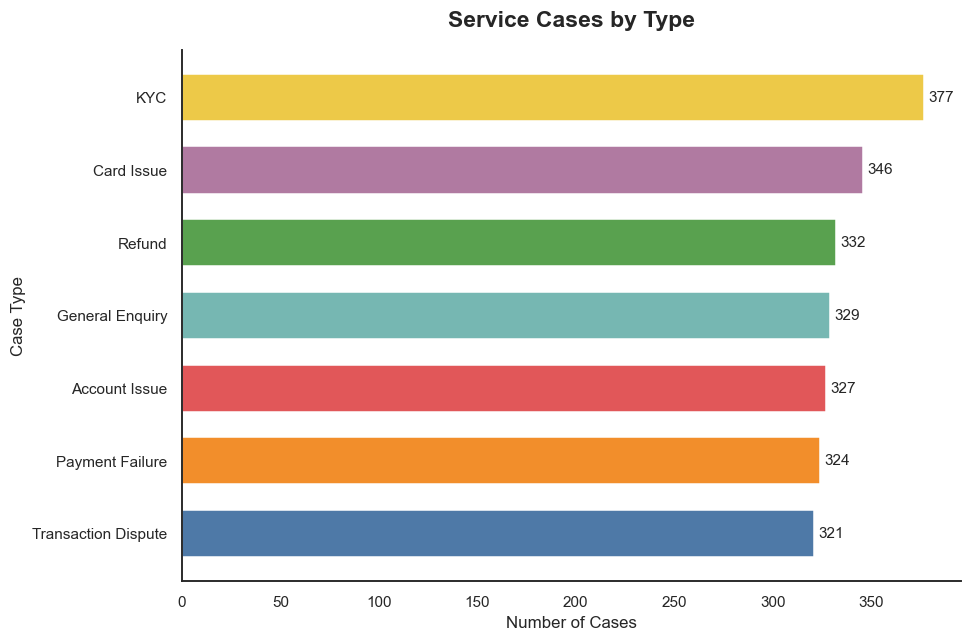

In [17]:
import matplotlib.pyplot as plt
import os

# Count cases by type
case_counts = service_cases["case_type"].value_counts().sort_values()

# Create different colors for each bar
colors = [
    "#4E79A7",  # Blue
    "#F28E2B",  # Orange
    "#E15759",  # Red
    "#76B7B2",  # Teal
    "#59A14F",  # Green
    "#B07AA1",  # Purple
    "#EDC948"   # Yellow
]

# Match colors with number of bars
bar_colors = colors[:len(case_counts)]

# Create chart
fig, ax = plt.subplots(figsize=(9, 6))

bars = ax.barh(
    case_counts.index,
    case_counts.values,
    color=bar_colors,
    edgecolor="white",
    height=0.65
)

# Display values on bars
ax.bar_label(
    bars,
    padding=3,
    fmt="%d",
    fontsize=10
)

# Title and labels
ax.set_title(
    "Service Cases by Type",
    pad=15,
    fontweight="bold",
    fontsize=15
)

ax.set_xlabel("Number of Cases")
ax.set_ylabel("Case Type")

# Remove gridlines
ax.grid(False)

# Remove top and right borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

# Save image
os.makedirs("visualizations", exist_ok=True)

plt.savefig(
    "visualizations/11_service_cases_by_type.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

## Chart 12 — SLA breaches by case type

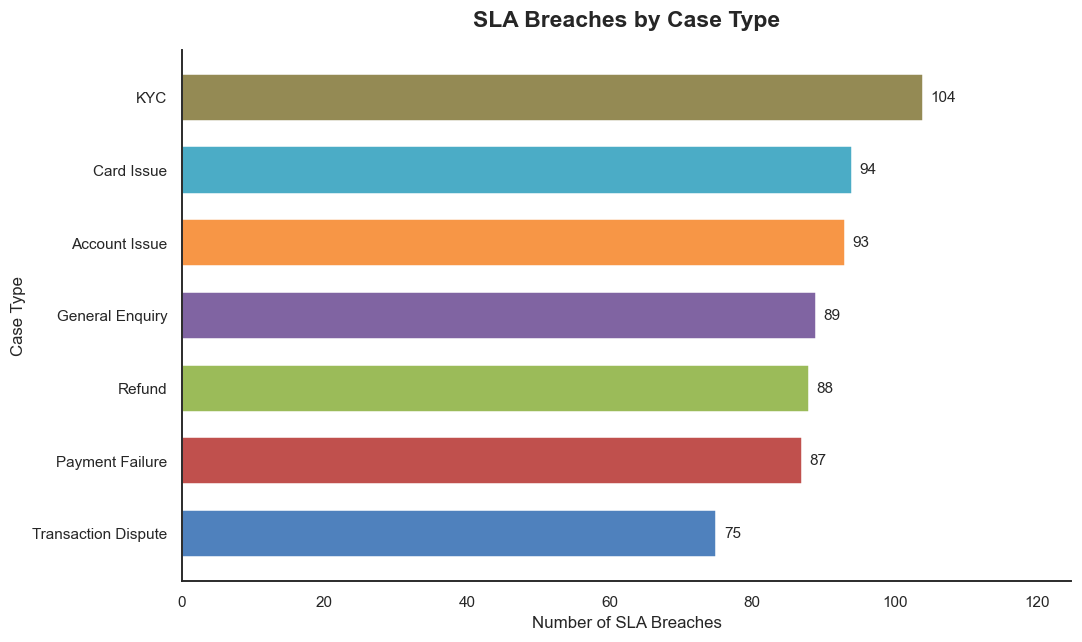

In [18]:
import matplotlib.pyplot as plt
import os

# Copy and clean service cases data
sla_data = service_cases.copy()

sla_data["sla_breached"] = (
    sla_data["sla_breached"]
    .astype(str)
    .str.strip()
    .str.lower()
    .map({"true": 1, "false": 0, "1": 1, "0": 0})
)

# Count breaches by case type
breaches = (
    sla_data.groupby("case_type")["sla_breached"]
    .sum()
    .sort_values()
)

os.makedirs("visualizations", exist_ok=True)

# Different color for each bar
colors = [
    "#4F81BD",  # Blue
    "#C0504D",  # Red
    "#9BBB59",  # Green
    "#8064A2",  # Purple
    "#F79646",  # Orange
    "#4BACC6",  # Cyan
    "#948A54"   # Brown
]

# Repeat colors if there are more case types
bar_colors = [colors[i % len(colors)] for i in range(len(breaches))]

# Create chart
fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.barh(
    breaches.index.astype(str),
    breaches.values,
    color=bar_colors,
    edgecolor="white",
    height=0.65
)

# Display counts
ax.bar_label(bars, padding=5, fmt="%.0f", fontsize=10)

ax.set_title(
    "SLA Breaches by Case Type",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Number of SLA Breaches")
ax.set_ylabel("Case Type")

# Remove gridlines
ax.grid(False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

max_breach = breaches.max()
ax.set_xlim(left=0, right=max(max_breach * 1.2, 1))

plt.tight_layout()

plt.savefig(
    "visualizations/12_sla_breaches.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

## Chart 13 — Average resolution time by priority

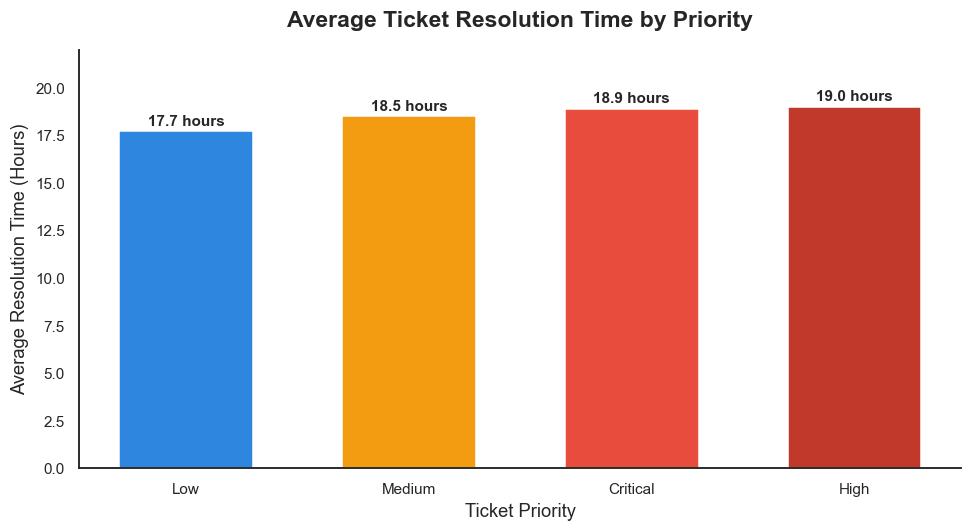

In [19]:
import matplotlib.pyplot as plt
import os

# Average resolution time by priority
priorities = ['Low', 'Medium', 'Critical', 'High']
avg_hours = [17.7, 18.5, 18.9, 19.0]

# Create the visualization folder if it doesn't exist
os.makedirs("visualizations", exist_ok=True)

# Create the chart
plt.figure(figsize=(9, 5))

bars = plt.bar(
    priorities,
    avg_hours,
    color=['#2E86DE', '#F39C12', '#E74C3C', '#C0392B'],
    width=0.6,
    edgecolor='white'
)

# Add values above the bars
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.15,
        f'{height:.1f} hours',
        ha='center',
        va='bottom',
        fontsize=10,
        fontweight='bold'
    )

# Titles and labels
plt.title(
    'Average Ticket Resolution Time by Priority',
    fontsize=15,
    fontweight='bold',
    pad=15
)
plt.xlabel('Ticket Priority', fontsize=12)
plt.ylabel('Average Resolution Time (Hours)', fontsize=12)

# Chart formatting
plt.ylim(0, 22)
plt.grid(False)  # Remove all grid lines
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)

plt.tight_layout()

# Save the chart
plt.savefig(
    'visualizations/average_resolution_by_priority.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()